## TODO List

- [ ] Compare the Multi-Layer Perceptron (MLP) with two variants of Convolutional Neural Networks (CNNs).

- [ ] Investigate what happens when a shape appears at a position that was not seen during training.

- [ ] Investigate how shuffling the pixels of all images affects model performance and classification accuracy.
- [] Replace the pooling by dilated convolutions and find out when pooling and when
dilation is the right choice.

In [9]:
import numpy as np
import torch
import torch
import torch.nn as nn

IMG = 28

SHAPE_NAMES = ["square", "ring", "plus", "cross"]


def draw_shape(kind, size):
    """
    Template (size x size) of the shape:
    0 = square, 1 = ring, 2 = plus, 3 = cross.
    """

    m = np.zeros((size, size), dtype=np.float32)
    c = (size - 1) / 2

    yy, xx = np.mgrid[:size, :size]

    if kind == 0:
        m[:] = 1.0

    elif kind == 1:
        r = np.hypot(yy - c, xx - c)
        m[(r <= size / 2) & (r >= size / 2 - 1.6)] = 1.0

    elif kind == 2:
        m[size // 2 - 1:size // 2 + 1, :] = 1.0
        m[:, size // 2 - 1:size // 2 + 1] = 1.0

    else:
        d = np.arange(size)
        m[d, d] = 1.0
        m[d, size - 1 - d] = 1.0
        m = np.maximum(m, np.roll(m, 1, axis=1))

    return m


def make_shapes(n_samples, size=9, noise=0.3, pos_range=None, seed=0):
    """
    Return images X (n, 1, 28, 28), float32,
    and labels y (n,), int64.

    The row and column of the upper-left corner of the shape
    are drawn uniformly from pos_range = (lo, hi).

    Default: (0, 28 - size), meaning anywhere.
    """

    lo, hi = pos_range if pos_range is not None else (0, IMG - size)

    rng = np.random.default_rng(seed)

    templates = [draw_shape(k, size) for k in range(4)]

    y = rng.integers(0, 4, n_samples)

    pos = rng.integers(lo, hi + 1, (n_samples, 2))

    X = np.zeros((n_samples, 1, IMG, IMG), dtype=np.float32)

    for i in range(n_samples):
        r, c = pos[i]
        X[i, 0, r:r + size, c:c + size] = templates[y[i]]

    X += noise * rng.standard_normal(X.shape).astype(np.float32)

    return (
        torch.from_numpy(X),
        torch.from_numpy(y.astype(np.int64))
    )

In [2]:
# Generate 2000 test images
X_test, y_test = make_shapes(2000, seed=99)

# Generate training datasets of different sizes
N_values = [100, 500, 1000, 2000, 5000]

training_sets = {}

for N in N_values:
    X_train, y_train = make_shapes(N, seed=100)
    training_sets[N] = (X_train, y_train)

In [7]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: torch.Size([5000, 1, 28, 28])
y_train shape: torch.Size([5000])
X_test shape: torch.Size([2000, 1, 28, 28])
y_test shape: torch.Size([2000])


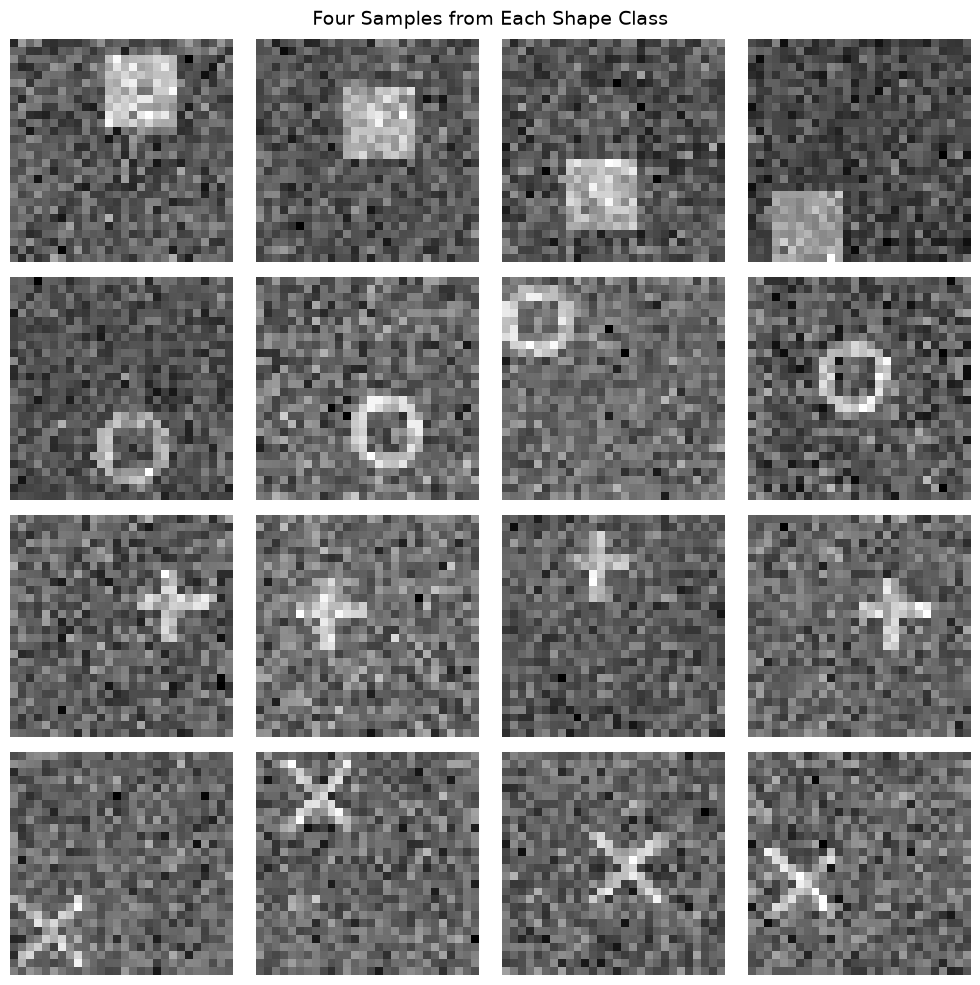

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for class_idx in range(4):
    # Find indices of images belonging to this class
    indices = torch.where(y_train == class_idx)[0][:4]

    for j, idx in enumerate(indices):
        axes[class_idx, j].imshow(X_train[idx, 0].numpy(), cmap="gray")
        axes[class_idx, j].axis("off")

        if j == 0:
            axes[class_idx, j].set_ylabel(
                SHAPE_NAMES[class_idx], fontsize=12
            )

plt.suptitle("Four Samples from Each Shape Class", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
class MLP(nn.Module):
    """
    MLP on the flattened image with n_layers hidden layers of width.
    """

    def __init__(self, width=64, n_layers=2, n_classes=4):
        super().__init__()

        layers = [nn.Flatten()]

        input_size = 28 * 28

        for _ in range(n_layers):
            layers.append(nn.Linear(input_size, width))
            layers.append(nn.ReLU())
            input_size = width

        layers.append(nn.Linear(input_size, n_classes))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

In [ ]:
class ConvNet(nn.Module):
    """
    Conv - Pool - Conv - Pool followed by the head
    'flatten' or 'global'.
    """

    def __init__(self, channels=8, head="flatten", n_classes=4):
        super().__init__()

        c = channels

        self.features = nn.Sequential(
            nn.Conv2d(1, c, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(c, 2*c, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        if head == "flatten":
            self.head = nn.Sequential(
                nn.Flatten(),
                nn.Linear(2*c*7*7, n_classes)
            )

        elif head == "global":
            self.head = nn.Sequential(
                nn.AdaptiveMaxPool2d(1),
                nn.Flatten(),
                nn.Linear(2*c, n_classes)
            )

        else:
            raise ValueError("head must be 'flatten' or 'global'")

    def forward(self, x):
        x = self.features(x)
        return self.head(x)

In [ ]:
class DilatedNet(nn.Module):
    """
    Dilated convolutions without pooling, followed by global max pooling.
    """

    def __init__(self, channels=8, dilations=(1, 2, 4), n_classes=4):
        super().__init__()

        layers = []
        c_in = 1

        for r in dilations:
            c_out = channels if c_in == 1 else 2 * channels

            layers.append(
                nn.Conv2d(
                    c_in,
                    c_out,
                    kernel_size=3,
                    padding=r,
                    dilation=r
                )
            )

            layers.append(nn.ReLU())

            c_in = c_out

        self.features = nn.Sequential(*layers)

        self.head = nn.Sequential(
            nn.AdaptiveMaxPool2d(1),
            nn.Flatten(),
            nn.Linear(2 * channels, n_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.head(x)